# Bicycle Rental Demand Analysis

## Project overview

Bicycle rental demand changes from day to day. This project explores how those changes relate to seasons and weather, then checks how much we can learn from averages and a simple outlier test.

**Research question:** How do weather conditions and seasons relate to bicycle rental demand, and how might unusual observations affect the conclusions?

The analysis uses Python, pandas, NumPy, Matplotlib and Seaborn. It follows a practical workflow: prepare the data, explore demand, compare groups, and assess the limits of the results.


## Contents

1. [Set up the analysis](#1-set-up-the-analysis)
2. [Load and inspect the data](#2-load-and-inspect-the-data)
3. [Explore high-demand days](#3-explore-high-demand-days)
4. [Compare seasons and weather](#4-compare-seasons-and-weather)
5. [Check group sizes and reliability](#5-check-group-sizes-and-reliability)
6. [Test sensitivity to unusual values](#6-test-sensitivity-to-unusual-values)
7. [Findings, limitations and next steps](#7-findings-limitations-and-next-steps)

## 1. Set up the analysis

Import the libraries used for data handling, summary statistics and plotting.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



## 2. Load and inspect the data

The CSV is loaded from this repository path:

[Projects / Bikes / bike.csv](https://github.com/tinashemungoshi/Projects/blob/main/Bikes/bike.csv)

Each row represents a recorded day. The notebook renames `yr`, `mnth` and `cnt` to `year`, `month` and `count`, then checks for missing values.

| Field | Role in the analysis |
| --- | --- |
| `count` (originally `cnt`) | Daily bicycle rentals |
| `season`, `weathersit` | Seasonal and weather categories |
| `year`, `month`, `weekday` | Calendar context |
| `holiday`, `workingday` | Day classifications |
| `temp`, `hum`, `windspeed` | Weather measurements; units are not verified here |
| `days_since_2011` | Time index supplied in the CSV |

The saved missing-value check reports no missing values. This check alone does not establish that dates, duplicates, category labels or measurement units are correct. The source URL points to a changeable branch rather than a fixed dataset version.

In [3]:
url = "https://raw.githubusercontent.com/tinashemungoshi/Projects/main/Bikes/bike.csv"

bike = pd.read_csv(url)

bike.head()


,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt,days_since_2011
0,WINTER,2011,JAN,NO HOLIDAY,SAT,NO WORKING DAY,MISTY,8.175849,80.5833,10.749882,985,0
1,WINTER,2011,JAN,NO HOLIDAY,SUN,NO WORKING DAY,MISTY,9.083466,69.6087,16.652113,801,1
2,WINTER,2011,JAN,NO HOLIDAY,MON,WORKING DAY,GOOD,1.229108,43.7273,16.636703,1349,2
3,WINTER,2011,JAN,NO HOLIDAY,TUE,WORKING DAY,GOOD,1.400000,59.0435,10.739832,1562,3
4,WINTER,2011,JAN,NO HOLIDAY,WED,WORKING DAY,GOOD,2.666979,43.6957,12.522300,1600,4


In [4]:
bike = bike.rename(
    columns={"yr":"year", "mnth":"month", "cnt":"count"}
    )

bike.head()

,season,year,month,holiday,weekday,workingday,weathersit,temp,hum,windspeed,count,days_since_2011
0,WINTER,2011,JAN,NO HOLIDAY,SAT,NO WORKING DAY,MISTY,8.175849,80.5833,10.749882,985,0
1,WINTER,2011,JAN,NO HOLIDAY,SUN,NO WORKING DAY,MISTY,9.083466,69.6087,16.652113,801,1
2,WINTER,2011,JAN,NO HOLIDAY,MON,WORKING DAY,GOOD,1.229108,43.7273,16.636703,1349,2
3,WINTER,2011,JAN,NO HOLIDAY,TUE,WORKING DAY,GOOD,1.400000,59.0435,10.739832,1562,3
4,WINTER,2011,JAN,NO HOLIDAY,WED,WORKING DAY,GOOD,2.666979,43.6957,12.522300,1600,4


In [5]:
bike.isnull().sum()

,0
season,0
year,0
month,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0
hum,0
windspeed,0


## 3. Explore high-demand days

Start by selecting working days with good weather, then look at days with more than 6,000 rentals. The threshold provides a way to explore busy days; it is not a statistical definition of an outlier.

The following cells filter the records, select relevant columns and calculate how often demand exceeds that threshold.

In [6]:
#1A. Create a DataFrame named working_good_df containing observations where the day is a working day ('WORKING DAY') and the weather is good ('GOOD').
working_good_df = bike.loc[(bike['workingday']=='WORKING DAY') & (bike['weathersit']=='GOOD')]
working_good_df.head()

,season,year,month,holiday,weekday,workingday,weathersit,temp,hum,windspeed,count,days_since_2011
2,WINTER,2011,JAN,NO HOLIDAY,MON,WORKING DAY,GOOD,1.229108,43.7273,16.636703,1349,2
3,WINTER,2011,JAN,NO HOLIDAY,TUE,WORKING DAY,GOOD,1.400000,59.0435,10.739832,1562,3
4,WINTER,2011,JAN,NO HOLIDAY,WED,WORKING DAY,GOOD,2.666979,43.6957,12.522300,1600,4
5,WINTER,2011,JAN,NO HOLIDAY,THU,WORKING DAY,GOOD,1.604356,51.8261,6.000868,1606,5
9,WINTER,2011,JAN,NO HOLIDAY,MON,WORKING DAY,GOOD,-0.910849,48.2917,14.958889,1321,9


In [7]:
#1B. Create a DataFrame named high_demand_df containing days where bicycle rentals exceeded 6,000.
high_demand_df = bike[bike['count']>6000]
high_demand_df.head()

,season,year,month,holiday,weekday,workingday,weathersit,temp,hum,windspeed,count,days_since_2011
184,SUMMER,2011,JUL,HOLIDAY,MON,NO WORKING DAY,MISTY,26.153349,63.7917,5.459106,6043,184
438,WINTER,2012,MAR,NO HOLIDAY,WED,WORKING DAY,GOOD,18.907500,50.7083,7.709154,6312,438
439,WINTER,2012,MAR,NO HOLIDAY,THU,WORKING DAY,GOOD,18.202500,57.9583,10.042161,6192,439
441,WINTER,2012,MAR,NO HOLIDAY,SAT,NO WORKING DAY,MISTY,16.165849,75.5833,7.417168,7836,441
443,WINTER,2012,MAR,NO HOLIDAY,MON,WORKING DAY,GOOD,17.615000,72.8750,10.875239,6153,443


In [8]:
#1C. From high_demand_df, select only the season, temp, weathersit and count columns.
high_demand_df[['season', 'temp', 'weathersit', 'count']]

,season,temp,weathersit,count
184,SUMMER,26.153349,MISTY,6043
438,WINTER,18.907500,GOOD,6312
439,WINTER,18.202500,GOOD,6192
441,WINTER,16.165849,MISTY,7836
443,WINTER,17.615000,GOOD,6153
...,...,...,...,...
679,FALL,10.290849,GOOD,6536
680,FALL,11.779151,GOOD,6852
681,FALL,14.795000,GOOD,6269
702,FALL,13.267500,GOOD,6234


In [9]:
#1D. Calculate the percentage of all recorded days that experienced more than 6,000 rentals.
sixk = round((bike['count']>6000).mean()*100, 2)
print(f"{sixk}% of all recorded days experienced more than 6,000 rentals")

24.62% of all recorded days experienced more than 6,000 rentals


### Why the full dataset still matters

The saved output shows 180 days above 6,000 rentals, or **24.62%** of recorded days. Looking only at those days would exclude most of the dataset.

That would introduce selection bias: the selected records would make typical demand look higher and could give a misleading picture of how weather and season relate to rental activity.

## 4. Compare seasons and weather

Compare the mean, median and standard deviation of rentals by season. Then summarise demand by weather category and by combinations of season and weather.

The chart helps compare weather categories within each season. These are descriptive comparisons across the available records, without adjusting for year or working-day status.

In [10]:
# 2A — Seasonal demand
# Calculate the mean, median and standard deviation of bicycle rental counts for each season.
# Your output should contain one row per season.

bike.groupby('season')['count'].agg(
    ['mean', 'median', 'std']
    ).reset_index().round(2)



,season,mean,median,std
0,FALL,4728.16,4634.5,1699.62
1,SPRING,4992.33,4941.5,1695.98
2,SUMMER,5644.30,5353.5,1459.80
3,WINTER,2604.13,2209.0,1399.94


In [11]:
# 2B — Weather conditions
# Calculate the average bicycle rental count for each weather category.
# Sort the results from the highest average rental count to the lowest.
avg_weather = round(bike.groupby('weathersit')['count'].mean().sort_values(ascending=False).reset_index(), 2)
avg_weather.head()


,weathersit,count
0,GOOD,4876.79
1,MISTY,4035.86
2,RAIN/SNOW/STORM,1803.29


In [12]:
# 2C — Multiple grouping variables
# Calculate the average bicycle rental count for every combination of season and weather category.
# Your result should allow you to compare weather conditions within each season.

sw = bike.groupby(['season', 'weathersit'])['count'].mean().reset_index().round(2)
sw.head()

,season,weathersit,count
0,FALL,GOOD,5043.56
1,FALL,MISTY,4654.00
2,FALL,RAIN/SNOW/STORM,1961.60
3,SPRING,GOOD,5548.55
4,SPRING,MISTY,4236.71


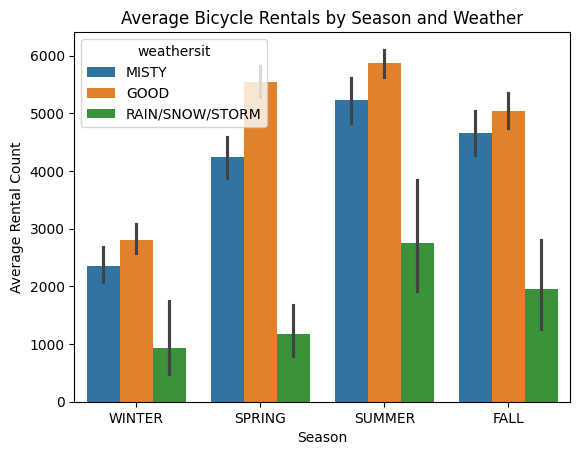

In [13]:
#2D — Visualisation
#Create a Seaborn bar plot comparing average bicycle rentals across seasons, with separate bars for each weather category.
#Include an appropriate chart title and axis labels.
sns.barplot(
    data=bike,
    x='season',
    y='count',
    hue='weathersit'
)
plt.title('Average Bicycle Rentals by Season and Weather')
plt.xlabel('Season')
plt.ylabel('Average Rental Count')
plt.show()

### What the summaries suggest

In the first seasonal table, summer has the highest mean demand (**5,644.30** rentals), while winter has the lowest (**2,604.13**). The weather summary reports the highest average for `GOOD` weather (**4,876.79**) and the lowest for `RAIN/SNOW/STORM` (**1,803.29**).

The retained chart suggests higher demand in good weather across the seasonal groups. However, the displayed season-and-weather table uses `.head()`, so it only shows the first five combinations. Group sizes in the next section help put the comparison in context.

These results show associations. They do not isolate the effect of weather: year, holidays, working-day status and other factors may also relate to demand.

The sensitivity comparison later in the notebook reproduces these same seasonal means after the outputs were refreshed.

## 5. Check group sizes and reliability

Averages are easier to interpret when we know how many observations sit behind them. Count the days in each season-and-weather combination, then compare the size and spread of the weather groups.

In [14]:
# 3A — Group sizes
# Calculate the number of daily observations for each combination of season and weathersit.
# Your output should contain three columns: season, weathersit and the number of observations.

bike.groupby(['season', 'weathersit'])['count'].size().reset_index(name='days')

,season,weathersit,days
0,FALL,GOOD,103
1,FALL,MISTY,65
2,FALL,RAIN/SNOW/STORM,10
3,SPRING,GOOD,113
4,SPRING,MISTY,68
5,SPRING,RAIN/SNOW/STORM,3
6,SUMMER,GOOD,136
7,SUMMER,MISTY,48
8,SUMMER,RAIN/SNOW/STORM,4
9,WINTER,GOOD,111


In [15]:
# 3B — Comparing group sizes and averages

# Create a summary DataFrame called weather_summary containing the following for each weather category:
# - Number of recorded days
# - Mean daily rental count
# - Standard deviation of daily rental counts

weather_summary = bike.groupby('weathersit')['count'].agg(['count', 'mean', 'std']).reset_index().round(2)
weather_summary.head()

,weathersit,count,mean,std
0,GOOD,463,4876.79,1879.48
1,MISTY,247,4035.86,1809.11
2,RAIN/SNOW/STORM,21,1803.29,1240.28


### What aggregation changes

The original `bike` DataFrame has one row per day. In `weather_summary`, each row represents a weather category and summarises multiple days.

This makes comparisons easier, but hides individual days, the shape of the distribution and variation over time. In this summary, the column named `count` is the **number of recorded days**, while `mean` describes average daily rentals.

### How much evidence supports each average?

The saved weather summary contains **463 good-weather days**, **247 misty days** and **21 rain/snow/storm days**. The adverse-weather category therefore has fewer observations supporting its average.

Some seasonal groups are smaller still: the saved group-size table shows only three adverse-weather days in spring and four each in summer and winter. A few unusual days could have a substantial effect on those means. Combining rain, snow and storms in one category also hides differences between those conditions.

For illustration, an average based on five days would generally be more sensitive to individual observations than one based on hundreds. That example is separate from the actual counts above.

### Why “always lower” goes too far

A lower group average does not mean every bad-weather day has fewer rentals than every good-weather day. The distributions may overlap.

The comparison also does not establish causation. Seasonal patterns, working-day status, holidays and changes between years could contribute to the differences. The defensible conclusion is that the saved summaries associate adverse weather with lower average demand.

## 6. Test sensitivity to unusual values

Use the interquartile range (IQR) to flag daily rental counts below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR`. Then compare the original data with two alternatives:

- **Trimmed:** exclude observations outside the boundaries.
- **Capped:** limit rental counts to the boundaries.

The final comparison checks whether either treatment changes the seasonal means. This uses one pair of boundaries for the whole dataset, rather than boundaries fitted within each season.

In [16]:
#4A — Detecting potential outliers
#Using the original bike DataFrame, calculate the IQR-based lower and upper boundaries for daily rental counts.
#Create a DataFrame named rental_outliers containing all observations outside those boundaries.
#Display the number of flagged observations.

Q3 = bike['count'].quantile(0.75) 
Q1 = bike['count'].quantile(0.25)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR


print(f"Lower Boundary: {lower:.2f}")
print(f"Upper Boundary: {upper:.2f}")


rental_outliers = bike.loc[(bike['count']>upper) | (bike['count']<lower)]

print(f"There are {rental_outliers.shape[0]} flagged observations.")

Lower Boundary: -1054.00
Upper Boundary: 10162.00
There are 0 flagged observations.


In [17]:
#4B — Comparing means
#Create a DataFrame named bike_trimmed that excludes observations identified as potential outliers.
#Compare the mean daily rental count in the original and trimmed datasets.
bike_trimmed = bike[~((bike['count']>upper) | (bike['count']<lower))]

bt_mean = bike_trimmed['count'].mean()
b_mean = bike['count'].mean()
print(f"The original bike dataset has a mean of: {b_mean:.2f} wheras the trimmed bike dataset has mean of: {bt_mean:.2f}.")

The original bike dataset has a mean of: 4504.35 wheras the trimmed bike dataset has mean of: 4504.35.


In [18]:
#4C — Capping extreme values
#Create a copy of bike named bike_capped.
#Using the IQR boundaries from 4A, cap extreme values in its count column without modifying the original DataFrame.
# Calculate the mean daily rental count after capping.
bike_capped = bike.copy()

bike_capped['count'] = bike_capped['count'].clip(upper=upper, lower=lower)

print(f"Mean daily rental count after capping: {bike_capped['count'].mean():.2f}")

Mean daily rental count after capping: 4504.35


In [19]:
#4D — Sensitivity analysis
#Compare the average rental count by season across the original, trimmed and capped datasets.
#Your goal is to determine whether treating outliers changes which season has the highest average rental demand.

original = bike.groupby('season')['count'].mean()
capped = bike_capped.groupby('season')['count'].mean()
trimmed = bike_trimmed.groupby('season')['count'].mean()

comparison = pd.DataFrame({
    'original':original,
    'capped':capped,
    'trimmed':trimmed
}).round(2).reset_index()

comparison


#treating outliers within this datset does not change which season has the highest average rental demand.

,season,original,capped,trimmed
0,FALL,4728.16,4728.16,4728.16
1,SPRING,4992.33,4992.33,4992.33
2,SUMMER,5644.30,5644.30,5644.30
3,WINTER,2604.13,2604.13,2604.13


### Interpreting the sensitivity check

The saved IQR output gives boundaries of **−1,054.00** and **10,162.00**, with **zero observations flagged**. The negative lower boundary cannot flag a non-negative rental count as unusually low.

The saved overall mean is **4,504.35** for the original, trimmed and capped data. With no records flagged, trimming and capping leave the rental counts unchanged, so identical means are expected. The saved seasonal comparison also reports identical values across the three treatments, with summer ranked highest.

The refreshed seasonal comparison matches the earlier summary: summer averages **5,644.30** rentals in all three versions. The original saved outputs contained conflicting figures; executing the unchanged code in order resolved that discrepancy.

Zero IQR flags does not mean the data contains no anomalies. The global rule may miss unusual values within a season, date issues, duplicate records or incorrect category labels.

## 7. Findings, limitations and next steps

### What this analysis shows

The retained outputs suggest that rental demand varies with season and weather. Summer ranks highest in both saved seasonal summaries, and good-weather days have the highest mean in the weather summary. The high-demand filter also shows why selecting only busy days would distort our view of typical demand.

The reliability checks add context: adverse-weather groups are small, aggregation hides daily variation, and a global IQR test does not cover every type of anomaly.

### Limits of the current results

- The results describe the CSV retrieved for this run; the live source may change.
- The current comparisons pool years and working-day categories together.
- Dates, duplicates, seasonal coding and weather units have not been verified against source documentation here.
- Means and standard deviations do not show the full rental distribution.
- The analysis describes associations and does not estimate causal effects or build a forecasting model.

### Next steps

1. Pin the dataset to a fixed repository revision so future runs use the same records.
2. Verify dates, duplicate records, seasonal labels and measurement units against the dataset documentation.
3. Compare demand within each year and working-day category.
4. Use distribution plots and quantiles to inspect spread, skew and overlap between groups.
5. Consider season-specific anomaly checks alongside the global IQR rule, and investigate flagged records before changing them.

These are proposed extensions, not analyses already completed in this notebook.